# Simple One hidden layer Neural Network

In [1]:
import torch
import torch.nn as nn
from torch import sigmoid
import matplotlib.pyplot as plt
import numpy as np
torch.manual_seed(0)

In [2]:
# function for plotting the model
def Plotstuff(X,Y,model,epoch,leg=True):

    plt.plot(X.numpy(), model(X).detach().numpy(), label = ('epoch ' + str(epoch)))
    plt.plot(X.numpy(), Y.numpy(), 'r')
    plt.xlabel('x')
    if leg == True:
        plt.legend()
    else:
        pass

## Neural Networks Module and training function

In [3]:
# Define the class net
class Net(nn.Module):

    # Constructor
    def __init__(self, D_in, H, D_out):
        super(Net,self).__init__()
        # hidden layer
        self.linear1 = nn.Linear(D_in,H)
        self.linear2 = nn.Linear(H,D_out)
        # Define the first linear layer as an attribute
        self.a1 = None
        self.l11 = None
        self.l2 = None

    # Prediction
    def forward(self, x):
        self.l1 = self.linear1(x)
        self.a1 = sigmoid(self.l1)
        self.l2 = self.linear2(self.a1)
        yhat = sigmoid(self.linear2(self.a1))
        return yhat

In [4]:
# Define the training function

def train(Y, X, model, opt, crt, epochs = 1000):
    cost = []
    total = 0
    for epoch in range(epochs):
        total = 0
        for y,x in zip(Y,X):
            yhat = model(x)
            loss = crt(yhat,y)
            loss.backward()
            opt.step()
            opt.zero_grad()
            total += loss.item()
        cost.append(total)
        if epoch % 300 == 0:
            Plotstuff(X,Y, model,epoch,leg=True)
            plt.show()
            model(X)
            plt.scatter(model.a1.detach().numpy()[:, 0],model.a1.detach().numpy()[:, 1],c=Y.numpy().reshape(-1))
            plt.title('activation')
            plt.show()
    return cost


## Make Some Data

In [5]:
X = torch.arange(-20,20,1).view(-1,1).type(torch.FloatTensor)
Y = torch.zeros(X.shape[0])
Y[(X[:, 0] > -4) & (X[:, 0] < 4)] = 1.0

## Define the Neural Networks, criterion function optimizer and train the model

In [6]:
# The loss function
def crt_cross(outputs, labels):
    out = -1 * torch.mean(labels * torch.log(outputs) + (1 - labels) * torch.log(1 - outputs))
    return out

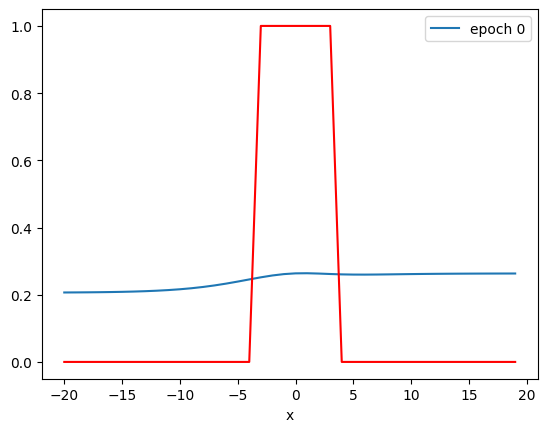

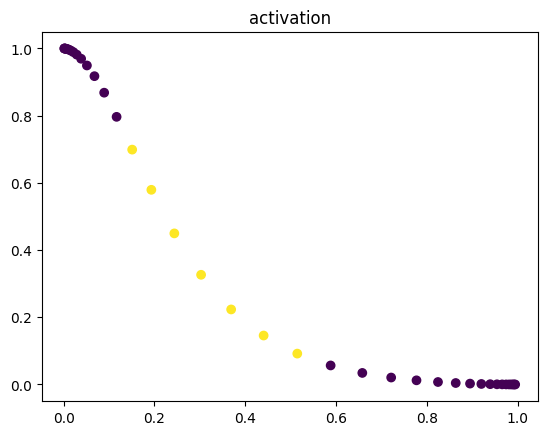

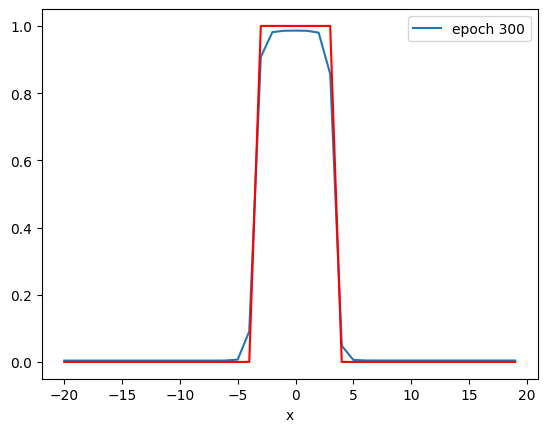

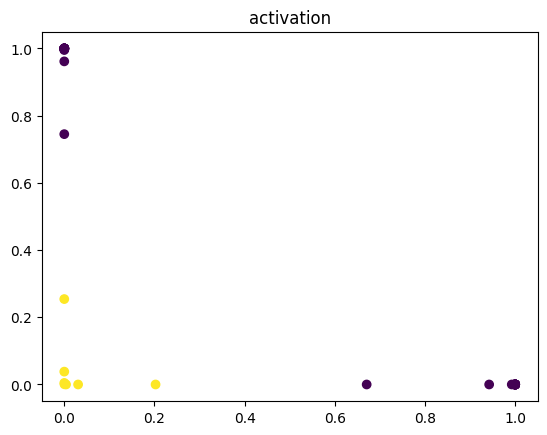

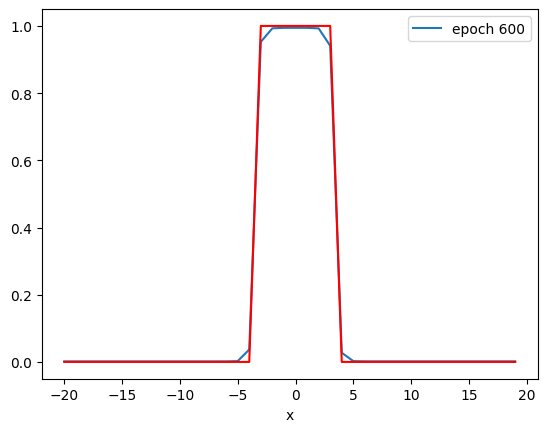

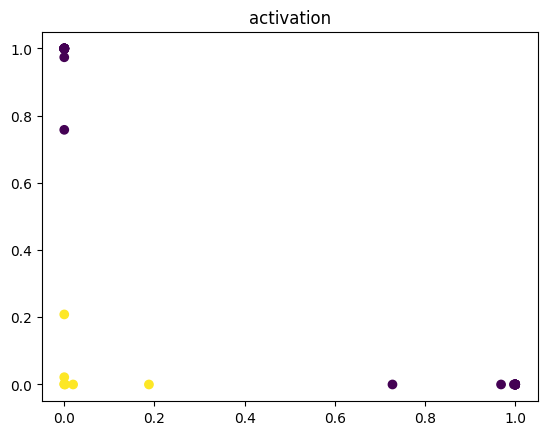

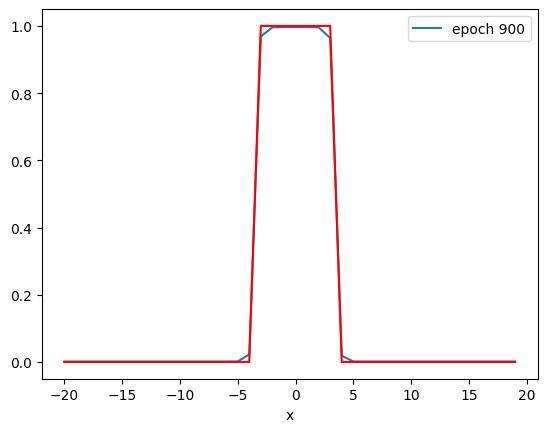

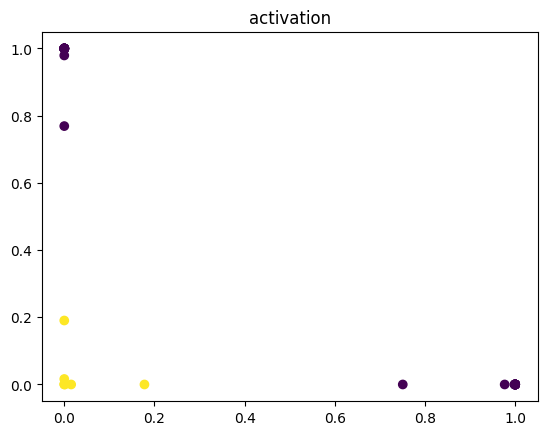

Text(0.5, 1.0, 'cross entropy loss')

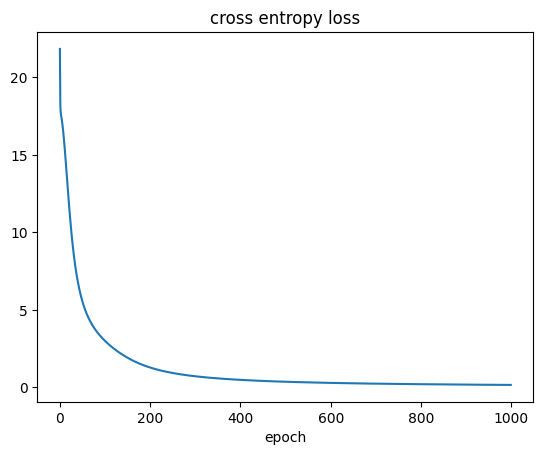

In [7]:
# size of input
D_in = 1
#size of hidden layer
H = 2
# number of outputs
D_out = 1
# learning rate
lr = 0.1
# create the model
model = Net(D_in,H,D_out)
# optimizer
opt = torch.optim.SGD(model.parameters(), lr=lr)
# train the model usein
cost_cross = train(Y,X,model,opt,crt_cross,epochs=1000)
# plot the loss
plt.plot(cost_cross)
plt.xlabel('epoch')
plt.title('cross entropy loss')

In [8]:
# make prediction 
x = torch.tensor([0.0])
yhat = model(x)
yhat


tensor([0.9969], grad_fn=<SigmoidBackward0>)

In [9]:
# threshold the prediction
yhat = yhat > 0.5
yhat

tensor([True])